In [2]:
import pickle
from pathlib import Path

import numpy as np
import jax
import jax.numpy as jnp
import jax.scipy as jsp
import scipy
import matplotlib.pyplot as plt
import operator
from jax import config
from functools import partial
from matplotlib.lines import Line2D
config.update("jax_enable_x64", True)

import os

import polars as pl
import statistics

from matplotlib.colors import CenteredNorm


from cmfa.emu_example import ordered_ilr_func


In [3]:
RESULTS_DIR = Path("..") / "data" / "results" / "tca_cycle"
PLOT_DIR = Path("..") / "figures"

In [4]:
true_flux = np.load(RESULTS_DIR / "true_flux.npy", allow_pickle=True).item()
true_id = np.load(RESULTS_DIR / "true_composition.npy", allow_pickle=True).item()
print(f"True flux: {true_flux}")
print(f"True isotopologue distribution: {true_id}")

True flux: {'v8': Array(0.215, dtype=float64), 'v1': Array(1., dtype=float64), 'v19': Array(0.05, dtype=float64), 'v20': Array(0.03, dtype=float64), 'v16': Array(0.07, dtype=float64), 'v17': Array(0.23, dtype=float64), 'v18': Array(0.12, dtype=float64), 'v2': Array(0.201, dtype=float64), 'v9': Array(0.296, dtype=float64), 'v3': Array(0.621, dtype=float64), 'v4': Array(0.621, dtype=float64), 'v5': Array(0.621, dtype=float64), 'v6': Array(0.592, dtype=float64), 'v11': Array(1.213, dtype=float64), 'v12': Array(0.296, dtype=float64), 'v13': Array(1.509, dtype=float64), 'v14': Array(1.735, dtype=float64), 'v15': Array(5.561, dtype=float64), 'v10': Array(0.475, dtype=float64), 'v7': Array(0.807, dtype=float64)}
True isotopologue distribution: {'lysx_123456': Array([0.01567147, 0.11709665, 0.24642148, 0.28673379, 0.21348085,
       0.10003428, 0.02056148], dtype=float64), 'valx_12345': Array([0.0128301 , 0.10251097, 0.27570439, 0.34531928, 0.21147698,
       0.05215829], dtype=float64), 'aspx

In [5]:
free_fluxes = jnp.load(RESULTS_DIR / "free_fluxes.npy", allow_pickle=True)
free_fluxes.shape

(125, 3)

In [6]:
target = np.array([[true_flux['v8'], true_flux['v2'], true_flux['v9']]])
true_flux_index= np.where(np.isclose(free_fluxes,target).all(axis=1))[0].item()
free_fluxes[true_flux_index]

Array([0.215, 0.201, 0.296], dtype=float64)

In [7]:
intensity_msts = jnp.load(RESULTS_DIR / "intensity_measurements.npy", allow_pickle=True)
type(intensity_msts)

list

In [8]:
true_ids = jnp.load(RESULTS_DIR / "true_isotopologue_distributions.npy", allow_pickle=True)
type(true_ids)

list

In [9]:
with open(RESULTS_DIR / "estimated_fluxes.pkl", "rb") as f:
    estimated_fluxes = pickle.load(f)

In [10]:
with open(RESULTS_DIR / "estimated_ids.pkl", "rb") as f:
    estimated_ids = pickle.load(f)

In [11]:
estimated_fluxes["trad"].shape

(125, 50, 3)

In [12]:
resid_trad = (free_fluxes[:, None, :] - estimated_fluxes["trad"][:, :, :])/free_fluxes[:, None, :]
resid_clr = (free_fluxes[:, None, :] - estimated_fluxes["clr"][:, :, :])/free_fluxes[:, None, :]
resid_ilr = (free_fluxes[:, None, :] - estimated_fluxes["ilr"][:, :, :])/free_fluxes[:, None, :]

mse_trad = (resid_trad ** 2).mean(axis=(0, 1))
mse_clr = (resid_clr ** 2).mean(axis=(0, 1))
mse_ilr = (resid_ilr ** 2).mean(axis=(0, 1))

mse_trad, mse_clr, mse_ilr

(Array([1.02822177, 0.00465171, 0.08663026], dtype=float64),
 Array([0.35113978, 0.00161571, 0.02026887], dtype=float64),
 Array([0.34921831, 0.00162295, 0.02031834], dtype=float64))

In [13]:
id_resid_trad = [
    [
        {k: true_ids[i][k] - est_val[k] for k in true_ids[0]}
        for est_val in trad_row
    ]
    for i, trad_row in enumerate(estimated_ids["trad"])
]
id_resid_clr = [
    [
        {k: true_ids[i][k] - est_val[k] for k in true_ids[0]}
        for est_val in trad_row
    ]
    for i, trad_row in enumerate(estimated_ids["clr"])
]
id_resid_ilr = [
    [
        {k: true_ids[i][k] - est_val[k] for k in true_ids[0]}
        for est_val in trad_row
    ]
    for i, trad_row in enumerate(estimated_ids["ilr"])
]

n_elements = len(id_resid_trad) * len(id_resid_trad[0])

id_mse_trad = {
    k: sum(row[col][k]**2 for row in id_resid_trad for col in range(len(row))) / n_elements
    for k in true_ids[0]
}
id_mse_clr = {
    k: sum(row[col][k]**2 for row in id_resid_clr for col in range(len(row))) / n_elements
    for k in true_ids[0]
}
id_mse_ilr = {
    k: sum(row[col][k]**2 for row in id_resid_ilr for col in range(len(row))) / n_elements
    for k in true_ids[0]
}


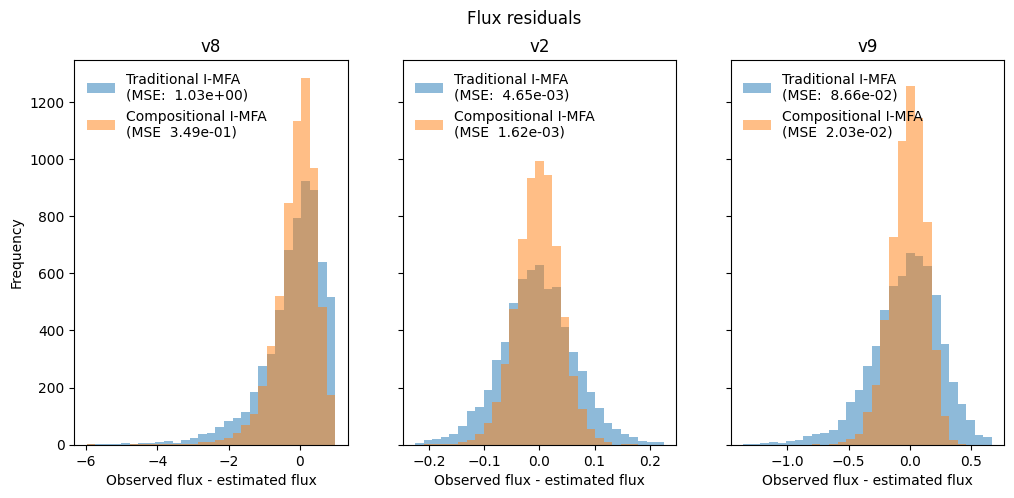

In [14]:
f, axes = plt.subplots(1, 3, figsize=[12, 5], sharey=True)
free_flux_numbers = jnp.array([8,2,9])
for (i, ax) in enumerate(axes):
    resid_trad_i = resid_trad[:, :, i].flatten()
    resid_comp_i = resid_ilr[:, :, i].flatten()
    xmin = np.quantile(np.concat([resid_trad_i, resid_comp_i]), 0.001)
    xmax = np.quantile(np.concat([resid_trad_i, resid_comp_i]), 0.999)
    bins = np.linspace(xmin, xmax, 30)
    h_trad = ax.hist(
        resid_trad_i, 
        bins=bins,
        alpha=0.5,
        label=f"Traditional I-MFA\n(MSE: {mse_trad[i]: .2e})" 
    )
    h_ilr = ax.hist(
        resid_comp_i, 
        bins=bins,
        alpha=0.5,
        label=f"Compositional I-MFA\n(MSE {mse_ilr[i]: .2e})" 
    )
    # ax.axvline(true_flux[flux_ix], color="red", label=f"True flux ({true_flux[flux_ix]})")
    ax.set(title=f"v{free_flux_numbers[i]}", xlabel="Observed flux - estimated flux")
    ax.legend(frameon=False, loc="upper left")
axes[0].set_ylabel("Frequency");

f.suptitle("Flux residuals");
f.savefig(PLOT_DIR / "flux_residuals_toy.png", bbox_inches="tight", dpi=200)

In [15]:
id_resid_trad_lysx = jnp.array([
    id_resid_trad[i][j]["lysx_123456"] 
    for i in range(len(free_fluxes)) 
    for j in range(50)
])

id_resid_ilr_lysx = jnp.array([
    id_resid_ilr[i][j]["lysx_123456"] 
    for i in range(len(free_fluxes)) 
    for j in range(50)
])

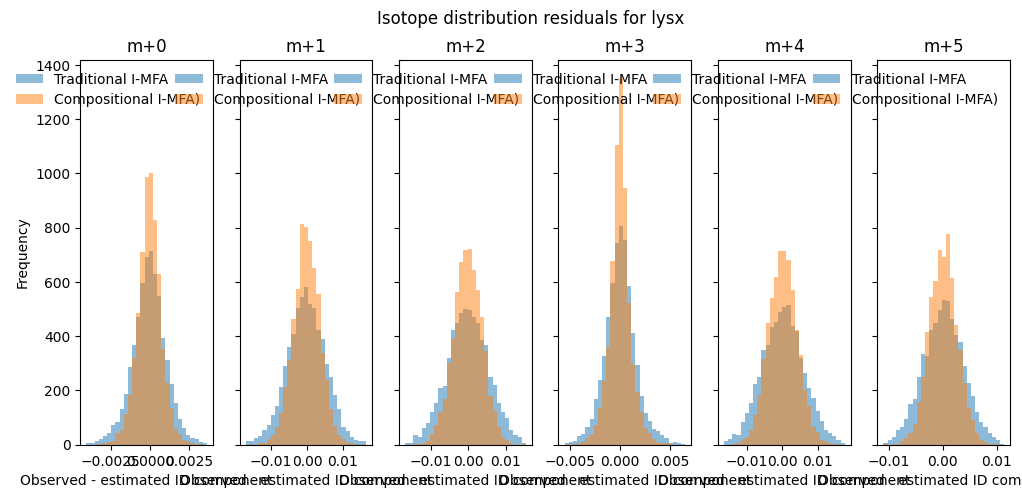

In [16]:
f, axes = plt.subplots(1, 6, figsize=[12, 5], sharey=True)

for (i, ax) in enumerate(axes):
    resid_trad_i = id_resid_trad_lysx[:, i].flatten()
    resid_comp_i = id_resid_ilr_lysx[:, i].flatten()
    xmin = np.quantile(resid_trad_i, 0.001)
    xmax = np.quantile(resid_trad_i, 0.999)
    bins = np.linspace(xmin, xmax, 30)
    h_trad = ax.hist(
        resid_trad_i, 
        bins=bins,
        alpha=0.5,
        label=f"Traditional I-MFA" 
    )
    h_ilr = ax.hist(
        resid_comp_i, 
        bins=bins,
        alpha=0.5,
        label=f"Compositional I-MFA)" 
    )
    # ax.axvline(true_flux[flux_ix], color="red", label=f"True flux ({true_flux[flux_ix]})")
    ax.set(title=f"m+{i}", xlabel="Observed - estimated ID component")
    ax.legend(frameon=False)
axes[0].set_ylabel("Frequency");

f.suptitle("Isotope distribution residuals for lysx");

In [17]:
with open(RESULTS_DIR / "gini_indices.npy", "rb") as f:
    gini_indices = pickle.load(f)
len(gini_indices)

125

In [18]:
gini_sums = [max(idx.values()) for idx in gini_indices]
diff_flux = ((resid_trad ** 2).mean(axis=1) - (resid_ilr ** 2).mean(axis=1))
# /(resid_trad ** 2).mean(axis=1)

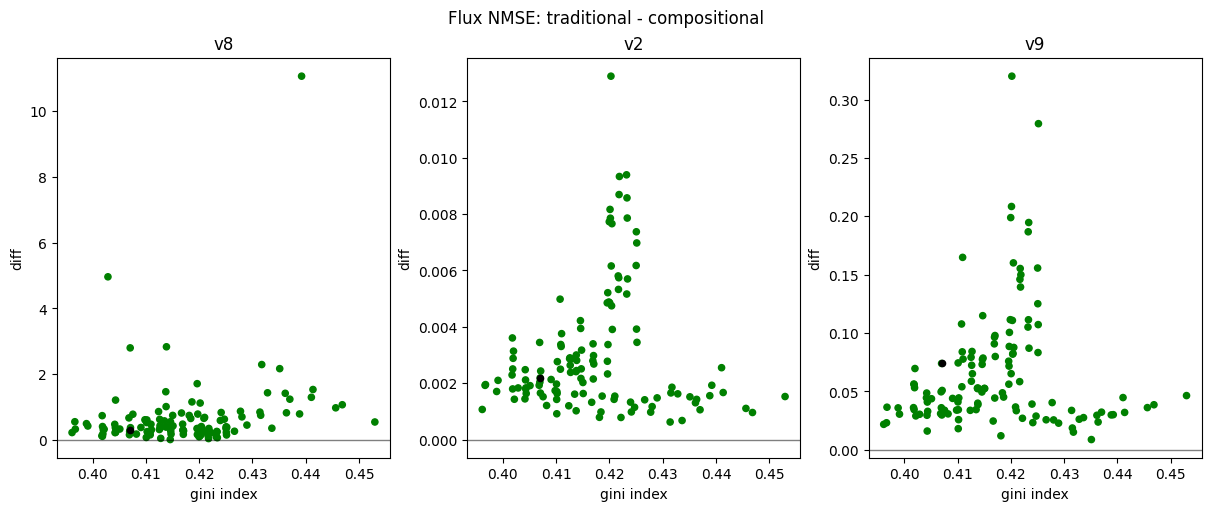

In [27]:
f, axes = plt.subplots(1, 3, figsize=[12, 5], layout= "constrained")
axes = axes.ravel()
point_size=20
for i in range(3):
    y_values = diff_flux[:,i]
    colors = np.where(y_values >= 0, 'green', 'red')
    axes[i].scatter(gini_sums, y_values, c=colors, s=point_size)
    axes[i].scatter(gini_sums[true_flux_index], y_values[true_flux_index], color="black", s=point_size)
    axes[i].axhline(0, color='black', lw=1, alpha=0.5, label="Reference flux")
    axes[i].set(xlabel="gini index", ylabel="diff", title=f"v{free_flux_numbers[i]}")
f.suptitle("Flux NMSE: traditional - compositional")

plt.show()

In [198]:
with open(RESULTS_DIR / "estimated_fluxes_ci.pkl", "rb") as f:
    estimated_fluxes_ci = pickle.load(f)
estimated_fluxes_ci["trad"].shape

(125, 50, 3, 2)

In [289]:
flux_ci_trad = estimated_fluxes_ci["trad"][true_flux_index,:,:,:].mean(axis=0)
flux_ci_ilr = estimated_fluxes_ci["ilr"][true_flux_index,:,:,:].mean(axis=0)

In [ ]:
flux = ["v8", "v2", "v9"]
print(f"{'Traditional':^42}")
print(f"{'Flux':<6} | {'Lower Bound':>15} | {'Upper Bound':>15}")
print("-" * 42)

for fl, (low, high) in zip(flux, flux_ci_trad):
    print(f"{fl:<6} | {low:15.4f} | {high:15.4f}")

               Traditional                
Flux   |     Lower Bound |     Upper Bound
------------------------------------------
v8     |          0.1053 |          0.3970
v2     |          0.0013 |       5783.0684
v9     |          0.0199 |          5.5585


In [ ]:
print(f"{'Compositional':^42}")
print(f"{'Flux':<6} | {'Lower Bound':>15} | {'Upper Bound':>15}")
print("-" * 42)

for fl, (low, high) in zip(flux, flux_ci_ilr):
    print(f"{fl:<6} | {low:15.4f} | {high:15.4f}")

              Compositional               
Flux   |     Lower Bound |     Upper Bound
------------------------------------------
v8     |          0.1720 |          0.2361
v2     |          0.0274 |          2.0918
v9     |          0.1617 |          0.5515
